# 04 — Exploratory Data Analysis

Understand the Atticus AOK dataset before or after training.

> **Kernel:** `Legal AI`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display

ROOT = Path().resolve().parent
with open(ROOT / 'config.yaml') as f:
    CFG = yaml.safe_load(f)

PROCESSED_DIR = ROOT / CFG['dataset']['processed_dir']

csv_path = PROCESSED_DIR / 'contracts_clean.csv'
if not csv_path.exists():
    raise FileNotFoundError('Run 01_prepare_data.ipynb first.')

df = pd.read_csv(csv_path)
print(f'Shape: {df.shape}')
display(df.head(3))

Shape: (20744, 5)


,text,label,label_id,contract_name,source
0,DISTRIBUTOR AGREEMENT,Document Name,8,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,json_answer
1,Electric City Corp.,Parties,39,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,json_answer
2,Electric City of Illinois L.L.C.,Parties,39,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,json_answer


## 1. Label distribution

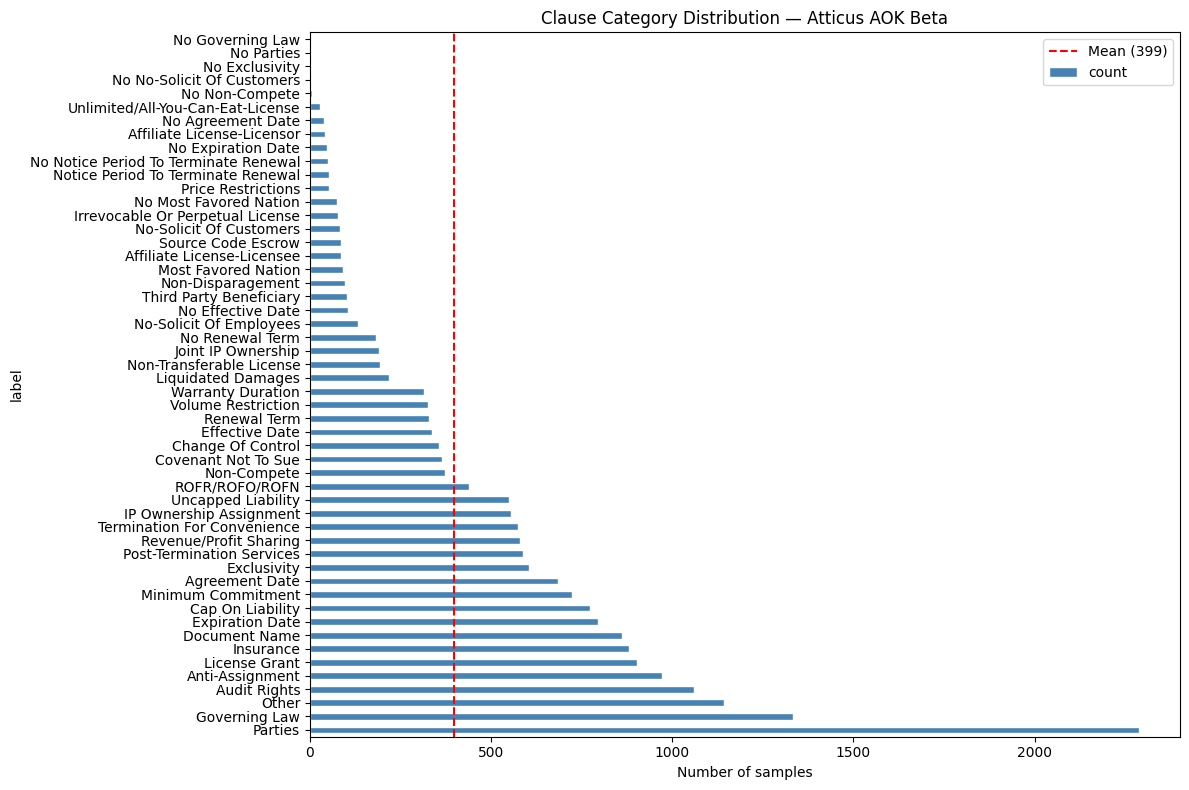

Classes          : 52
Most common      : Parties (2,287)
Least common     : No Exclusivity (1)
Imbalance ratio  : 2287.0x


In [2]:
counts = df['label'].value_counts()

fig, ax = plt.subplots(figsize=(12, 8))
counts.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Number of samples')
ax.set_title('Clause Category Distribution — Atticus AOK Beta')
ax.axvline(counts.mean(), color='red', linestyle='--', label=f'Mean ({counts.mean():.0f})')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Classes          : {df["label"].nunique()}')
print(f'Most common      : {counts.idxmax()} ({counts.max():,})')
print(f'Least common     : {counts.idxmin()} ({counts.min():,})')
print(f'Imbalance ratio  : {counts.max()/counts.min():.1f}x')

## 2. Text length distribution

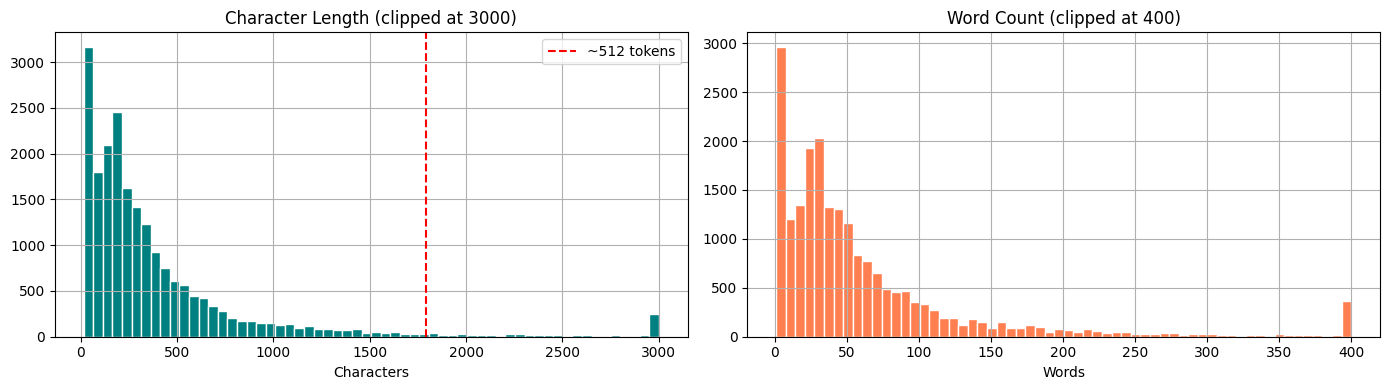

,char_len,word_len
count,20744.0,20744.0
mean,426.0,67.1
std,668.3,105.2
min,16.0,1.0
25%,121.0,19.0
50%,240.0,38.0
75%,470.0,75.0
max,15526.0,2612.0



2.3% of clauses exceed ~512 tokens (will be truncated)


In [3]:
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df['char_len'].clip(upper=3000).hist(bins=60, ax=axes[0], color='teal', edgecolor='white')
axes[0].axvline(512*3.5, color='red', linestyle='--', label='~512 tokens')
axes[0].set_title('Character Length (clipped at 3000)')
axes[0].set_xlabel('Characters')
axes[0].legend()

df['word_len'].clip(upper=400).hist(bins=60, ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Word Count (clipped at 400)')
axes[1].set_xlabel('Words')

plt.tight_layout()
plt.show()

display(df[['char_len', 'word_len']].describe().round(1))

pct_over_512 = (df['word_len'] > 350).mean() * 100
print(f'\n{pct_over_512:.1f}% of clauses exceed ~512 tokens (will be truncated)')

## 3. Average clause length by category

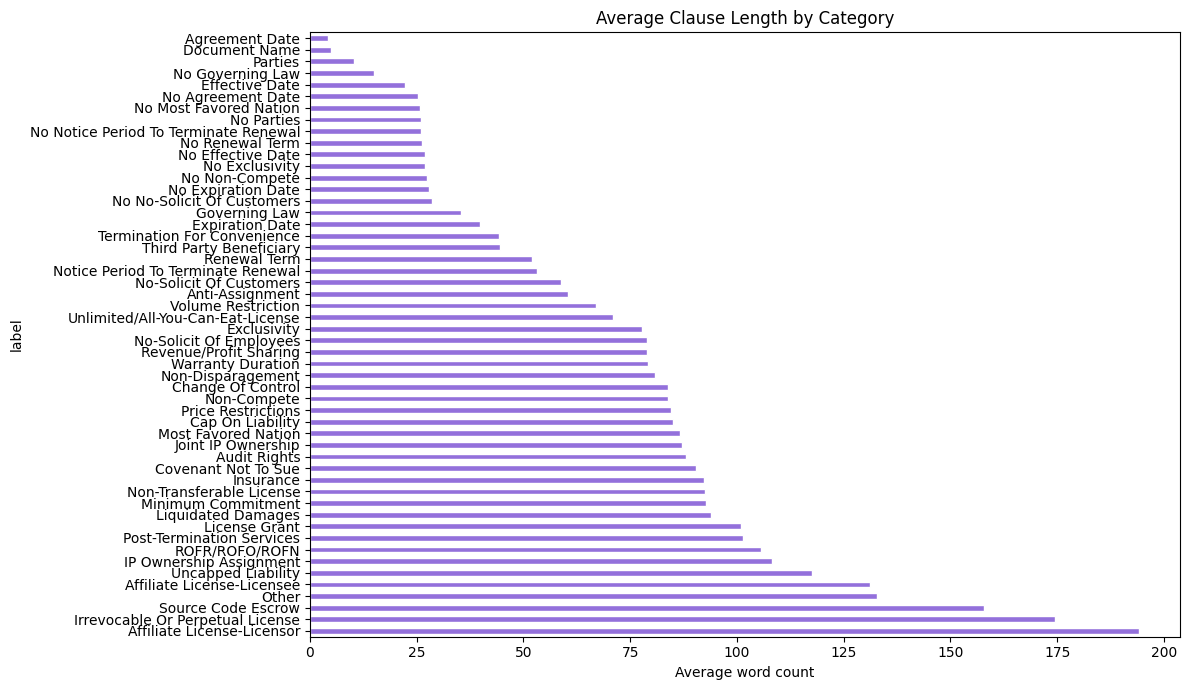

In [4]:
avg_len = df.groupby('label')['word_len'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))
avg_len.plot(kind='barh', ax=ax, color='mediumpurple', edgecolor='white')
ax.set_xlabel('Average word count')
ax.set_title('Average Clause Length by Category')
plt.tight_layout()
plt.show()

## 4. Sample clauses

In [5]:
SHOW_CATEGORIES = [
    'Governing Law', 'Non-Compete', 'Uncapped Liability',
    'Arbitration', 'IP Ownership Assignment',
]

for cat in SHOW_CATEGORIES:
    sub = df[df['label'] == cat]
    if sub.empty:
        continue
    sample = sub.sample(1, random_state=42)['text'].iloc[0]
    print(f'\n{'─'*70}')
    print(f'[{cat}]  ({len(sub):,} samples)')
    print(f'{'─'*70}')
    print(sample[:400] + ('...' if len(sample) > 400 else ''))


──────────────────────────────────────────────────────────────────────
[Governing Law]  (1,334 samples)
──────────────────────────────────────────────────────────────────────
British Columbia,Canada

──────────────────────────────────────────────────────────────────────
[Non-Compete]  (374 samples)
──────────────────────────────────────────────────────────────────────
['Except as expressly contemplated by this Agreement (including Article XIII hereof) and subject to Section 13.1 hereof, King shall not promote, market or distribute any product containing metformin hydrochloride as the sole active ingredient in the Territory during the Term of this Agreement, other than the Product.']

──────────────────────────────────────────────────────────────────────
[Uncapped Liability]  (549 samples)
──────────────────────────────────────────────────────────────────────
['EXCEPT IN THE EVENT OF A BREACH OF SECTION 11, NEITHER PARTY SHALL BE LIABLE FOR SPECIAL, INCIDENTAL OR CONSEQUENTIAL DAMAGES 

## 5. Class imbalance — should we use weighted loss?

In [6]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(df['label_id'])
weights = compute_class_weight('balanced', classes=classes, y=df['label_id'])
weight_df = pd.DataFrame({'label': [df[df['label_id']==i]['label'].iloc[0] for i in classes],
                           'weight': weights}).sort_values('weight', ascending=False)

print('Class weights (balanced):')
print(weight_df.to_string(index=False))

print('\n💡 To use in training, pass class_weight to the Trainer via a custom loss.')
print('   Highly imbalanced classes (weight > 3.0) may benefit most.')

Class weights (balanced):
                                label     weight
                     No Governing Law 398.923077
                           No Parties 398.923077
                       No Exclusivity 398.923077
           No No-Solicit Of Customers 199.461538
                       No Non-Compete  79.784615
    Unlimited/All-You-Can-Eat-License  14.774929
                    No Agreement Date  10.228797
           Affiliate License-Licensor   9.729831
                   No Expiration Date   8.487725
No Notice Period To Terminate Renewal   7.822021
   Notice Period To Terminate Renewal   7.671598
                   Price Restrictions   7.671598
               No Most Favored Nation   5.390852
     Irrevocable Or Perpetual License   5.180819
              No-Solicit Of Customers   4.864916
                   Source Code Escrow   4.638640
           Affiliate License-Licensee   4.585323
                  Most Favored Nation   4.383770
                    Non-Disparagement   4.0